In [1]:
import pandas as pd

# 저장한 데이터 불러오기
train = pd.read_csv("data/processed/train.csv")
valid = pd.read_csv("data/processed/valid.csv")
test = pd.read_csv("data/processed/test.csv")

# 데이터 확인
print("학습 데이터:", train.shape)
print("검증 데이터:", valid.shape)
print("테스트 데이터:", test.shape)

학습 데이터: (38436, 10)
검증 데이터: (19224, 10)
테스트 데이터: (19212, 10)


In [2]:
# 첫 번째 기준 예측 모
# 기준 모델: 작년 같은 달 사용량으로 예측
baseline = valid.copy()

baseline["예측사용량"] = baseline["lag_12"]

print(
    baseline[
        ["날짜", "시군구", "계약종별", "사용량", "예측사용량"]
    ].head(10)
)

           날짜  시군구 계약종별      사용량      예측사용량
0  2024-01-01  강릉시  가로등  2365255  2463458.0
1  2024-02-01  강릉시  가로등  2230718  2289572.0
2  2024-03-01  강릉시  가로등  2085862  2158138.0
3  2024-04-01  강릉시  가로등  2069044  2163920.0
4  2024-05-01  강릉시  가로등  1919984  2024211.0
5  2024-06-01  강릉시  가로등  1880213  1987989.0
6  2024-07-01  강릉시  가로등  1860095  1982549.0
7  2024-08-01  강릉시  가로등  1951307  2075244.0
8  2024-09-01  강릉시  가로등  2020838  2157483.0
9  2024-10-01  강릉시  가로등  2086775  2259569.0


In [3]:
#  MAE 성능 계산
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 실제값과 예측값
y_true = baseline["사용량"]
y_pred = baseline["예측사용량"]

# 성능 계산
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"MAE: {mae:,.0f} kWh")
print(f"RMSE: {rmse:,.0f} kWh")

MAE: 1,735,679 kWh
RMSE: 9,826,034 kWh


In [4]:
# 계약종별 성능 확인
# 각 행의 절대오차 계산
baseline["절대오차"] = (
    baseline["사용량"] - baseline["예측사용량"]
).abs()

# 계약종별 평균 절대오차
contract_mae = (
    baseline.groupby("계약종별")["절대오차"]
    .mean()
    .sort_values(ascending=False)
)

print(contract_mae.round(0))

계약종별
산업용    6980102.0
일반용    2214275.0
주택용    1841358.0
농사용     457093.0
심 야     401265.0
교육용     211527.0
가로등      38551.0
Name: 절대오차, dtype: float64


In [5]:
# Random Forest 모델 만들기
# 입력 변수와 정답 분리
# 모델에 사용할 입력 변수
features = [
    "연도",
    "월",
    "lag_1",
    "lag_12"
]

# 입력 데이터
X_train = train[features]
X_valid = valid[features]

# 정답 데이터
y_train = train["사용량"]
y_valid = valid["사용량"]

print("학습 입력:", X_train.shape)
print("학습 정답:", y_train.shape)
print("검증 입력:", X_valid.shape)
print("검증 정답:", y_valid.shape)

학습 입력: (38436, 4)
학습 정답: (38436,)
검증 입력: (19224, 4)
검증 정답: (19224,)


In [6]:
# Random Forest 학습
from sklearn.ensemble import RandomForestRegressor

# Random Forest 모델 생성
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# 모델 학습
rf_model.fit(X_train, y_train)

print("Random Forest 학습 완료!")

Random Forest 학습 완료!


In [7]:
# 2024년 검증 데이터 예측
rf_pred = rf_model.predict(X_valid)

# 실제값과 예측값 비교
result = valid[
    ["날짜", "시군구", "계약종별", "사용량"]
].copy()

result["예측사용량"] = rf_pred

print(result.head(10))

           날짜  시군구 계약종별      사용량         예측사용량
0  2024-01-01  강릉시  가로등  2365255  2.449007e+06
1  2024-02-01  강릉시  가로등  2230718  2.242617e+06
2  2024-03-01  강릉시  가로등  2085862  2.095655e+06
3  2024-04-01  강릉시  가로등  2069044  2.081403e+06
4  2024-05-01  강릉시  가로등  1919984  1.971159e+06
5  2024-06-01  강릉시  가로등  1880213  1.961336e+06
6  2024-07-01  강릉시  가로등  1860095  1.973536e+06
7  2024-08-01  강릉시  가로등  1951307  2.089746e+06
8  2024-09-01  강릉시  가로등  2020838  2.156442e+06
9  2024-10-01  강릉시  가로등  2086775  2.253977e+06


In [8]:
# 표시 형식 변경
pd.options.display.float_format = "{:,.0f}".format

In [9]:
# Random Forest 성능 평가

rf_mae = mean_absolute_error(y_valid, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_pred))

print("=== Random Forest 성능 ===")
print(f"MAE: {rf_mae:,.0f} kWh")
print(f"RMSE: {rf_rmse:,.0f} kWh")

=== Random Forest 성능 ===
MAE: 1,545,316 kWh
RMSE: 7,996,678 kWh


In [10]:
# 기준 모델과 Random Forest 비교

comparison = pd.DataFrame({
    "모델": ["기준 모델", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse]
})

print(comparison.to_string(index=False))

# 기준 모델 대비 MAE 개선율
improvement = (mae - rf_mae) / mae * 100

print(f"\nMAE 개선율: {improvement:.2f}%")

           모델       MAE      RMSE
        기준 모델 1,735,679 9,826,034
Random Forest 1,545,316 7,996,678

MAE 개선율: 10.97%


In [11]:
# 모델 개선-지역과 계약종별 추가
# 범주형 변수 변환
# STEP 24-1: 지역과 계약종별 변수 추가

# 숫자형 변수
numeric_features = [
    "연도", "월", "lag_1", "lag_12"
]

# 범주형 변수
categorical_features = [
    "시도", "시군구", "계약종별"
]

# 학습 데이터 변환
X_train_v2 = pd.get_dummies(
    train[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=int
)

# 검증 데이터 변환
X_valid_v2 = pd.get_dummies(
    valid[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=int
)

# 학습 데이터의 열 구조에 맞추기
X_valid_v2 = X_valid_v2.reindex(
    columns=X_train_v2.columns,
    fill_value=0
)

print("기존 입력 변수:", X_train.shape[1])
print("개선 입력 변수:", X_train_v2.shape[1])
print("학습 데이터:", X_train_v2.shape)
print("검증 데이터:", X_valid_v2.shape)

기존 입력 변수: 4
개선 입력 변수: 235
학습 데이터: (38436, 235)
검증 데이터: (19224, 235)


In [12]:
# 개선된 Random Forest 학습하기
# STEP 24-2: 개선된 Random Forest 학습

rf_model_v2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# 개선된 입력 데이터로 학습
rf_model_v2.fit(X_train_v2, y_train)

print("개선된 Random Forest 학습 완료!")

개선된 Random Forest 학습 완료!


In [13]:
# 개선된 모델의 성능 평가
# 2024년 검증 데이터 예측
rf_pred_v2 = rf_model_v2.predict(X_valid_v2)

# MAE와 RMSE 계산
rf_mae_v2 = mean_absolute_error(y_valid, rf_pred_v2)
rf_rmse_v2 = np.sqrt(
    mean_squared_error(y_valid, rf_pred_v2)
)

print("=== 개선된 Random Forest 성능 ===")
print(f"MAE: {rf_mae_v2:,.0f} kWh")
print(f"RMSE: {rf_rmse_v2:,.0f} kWh")

=== 개선된 Random Forest 성능 ===
MAE: 1,421,476 kWh
RMSE: 7,564,612 kWh


In [14]:
# 세 모델 비교하기
comparison = pd.DataFrame({
    "모델": [
        "기준 모델",
        "Random Forest v1",
        "Random Forest v2"
    ],
    "MAE": [mae, rf_mae, rf_mae_v2],
    "RMSE": [rmse, rf_rmse, rf_rmse_v2]
})

print(comparison.to_string(index=False))

# 기존 Random Forest 대비 개선율
improvement_v2 = (
    (rf_mae - rf_mae_v2) / rf_mae * 100
)

print(f"\nv1 대비 MAE 개선율: {improvement_v2:.2f}%")

              모델       MAE      RMSE
           기준 모델 1,735,679 9,826,034
Random Forest v1 1,545,316 7,996,678
Random Forest v2 1,421,476 7,564,612

v1 대비 MAE 개선율: 8.01%


In [15]:
# AI가 중요하게 생각하는 변수 중요도 확인
# STEP 25-1: 변수 중요도 분석

importance = pd.DataFrame({
    "변수": X_train_v2.columns,
    "중요도": rf_model_v2.feature_importances_
})

# 중요도가 높은 순서대로 정렬
importance = importance.sort_values(
    by="중요도",
    ascending=False
)

# 상위 15개 변수 확인
print(importance.head(15).to_string(index=False))

        변수  중요도
     lag_1    1
    lag_12    0
    시도_경기도    0
         월    0
   시군구_평택시    0
        연도    0
   시군구_이천시    0
   시도_경상북도    0
   시도_전라남도    0
   시도_충청남도    0
  계약종별_산업용    0
  계약종별_일반용    0
   시군구_여수시    0
시도_세종특별자치시    0
   시군구_당진시    0


In [16]:
# 변수 중요도를 소수점 6자리까지 출력
print(
    importance.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

        변수      중요도
     lag_1 0.565024
    lag_12 0.430678
    시도_경기도 0.001425
         월 0.000588
   시군구_평택시 0.000314
        연도 0.000214
   시군구_이천시 0.000189
   시도_경상북도 0.000187
   시도_전라남도 0.000127
   시도_충청남도 0.000124
  계약종별_산업용 0.000114
  계약종별_일반용 0.000113
   시군구_여수시 0.000094
시도_세종특별자치시 0.000085
   시군구_당진시 0.000070


In [17]:
# 2025 최종 테스트 | 세 모델 비교
# 2025년 테스트 데이터 준비

# 테스트 데이터도 학습 데이터와 동일하게 변환
X_test_v2 = pd.get_dummies(
    test[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=int
)

# 학습 데이터의 열 구조와 동일하게 맞추기
X_test_v2 = X_test_v2.reindex(
    columns=X_train_v2.columns,
    fill_value=0
)

# 테스트 데이터 정답
y_test = test["사용량"]

print("학습 입력:", X_train_v2.shape)
print("테스트 입력:", X_test_v2.shape)
print("테스트 정답:", y_test.shape)

학습 입력: (38436, 235)
테스트 입력: (19212, 235)
테스트 정답: (19212,)


In [18]:
# 2025년 최종 예측

# 학습된 모델로 테스트 데이터 예측
rf_test_pred = rf_model_v2.predict(X_test_v2)

# MAE, RMSE 계산
test_mae = mean_absolute_error(
    y_test, rf_test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_test_pred)
)

# 기준 모델 성능
baseline_test_mae = mean_absolute_error(
    y_test, test["lag_12"]
)

baseline_test_rmse = np.sqrt(
    mean_squared_error(y_test, test["lag_12"])
)

print("=== 2025년 최종 테스트 ===")

print("\n기준 모델")
print(f"MAE: {baseline_test_mae:,.0f} kWh")
print(f"RMSE: {baseline_test_rmse:,.0f} kWh")

print("\nRandom Forest v2")
print(f"MAE: {test_mae:,.0f} kWh")
print(f"RMSE: {test_rmse:,.0f} kWh")

improvement_test = (
    (baseline_test_mae - test_mae)
    / baseline_test_mae * 100
)

print(f"\n기준 모델 대비 MAE 개선율: {improvement_test:.2f}%")

=== 2025년 최종 테스트 ===

기준 모델
MAE: 1,434,528 kWh
RMSE: 8,335,193 kWh

Random Forest v2
MAE: 1,369,387 kWh
RMSE: 7,618,891 kWh

기준 모델 대비 MAE 개선율: 4.54%


In [19]:
# 모델 저장
import joblib
from pathlib import Path

# 모델 저장 폴더 생성
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# 모델과 입력 변수 목록 저장
joblib.dump(
    {
        "model": rf_model_v2,
        "features": X_train_v2.columns.tolist()
    },
    model_dir / "random_forest_v2.joblib"
)

print("모델 저장 완료!")

모델 저장 완료!


In [20]:
# 저장한 모델 불러오기
saved = joblib.load(
    "models/random_forest_v2.joblib"
)

loaded_model = saved["model"]
loaded_features = saved["features"]

# 저장된 모델로 다시 예측
loaded_pred = loaded_model.predict(
    X_test_v2[loaded_features]
)

# 기존 예측과 같은지 확인
print(
    "예측 결과 일치:",
    np.allclose(rf_test_pred, loaded_pred)
)

예측 결과 일치: True


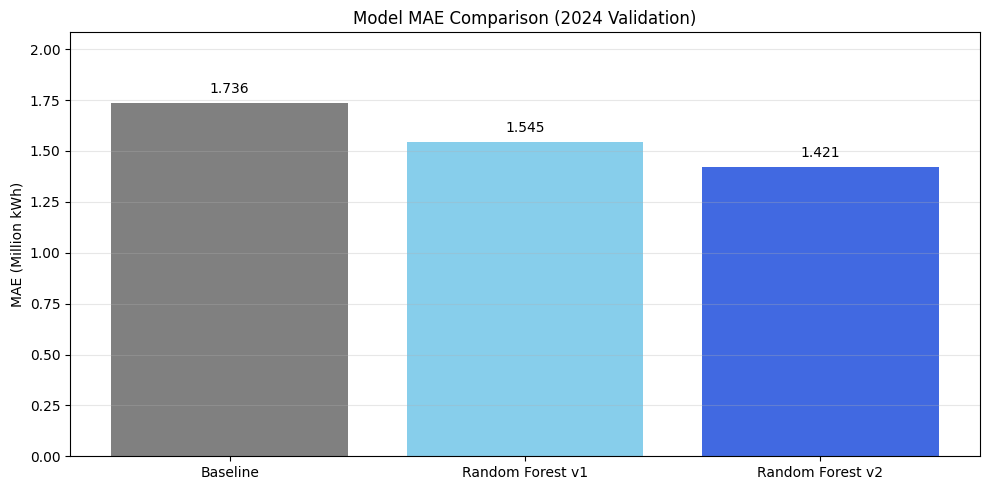

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 모델 이름
model_names = [
    "Baseline",
    "Random Forest v1",
    "Random Forest v2"
]

# MAE 값 (백만 kWh 단위)
mae_values = np.array([
    mae,
    rf_mae,
    rf_mae_v2
]) / 1_000_000

# 그래프 생성
plt.figure(figsize=(10, 5))

bars = plt.bar(
    model_names,
    mae_values,
    color=["gray", "skyblue", "royalblue"]
)

# 막대 위에 수치 표시
plt.bar_label(bars, fmt="%.3f", padding=5)

plt.title("Model MAE Comparison (2024 Validation)")
plt.ylabel("MAE (Million kWh)")
plt.ylim(0, max(mae_values) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

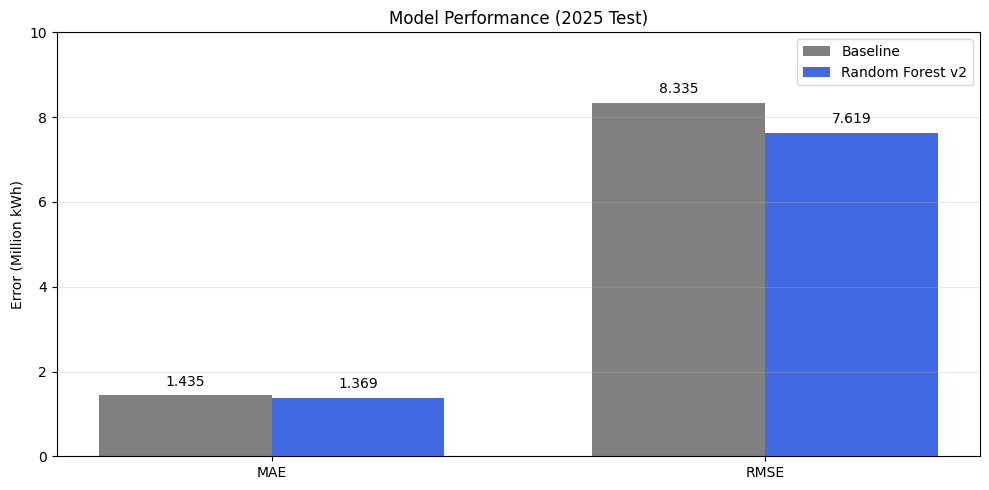

In [23]:
# 최종 테스트 성능 비교

metrics = ["MAE", "RMSE"]

baseline_values = np.array([
    baseline_test_mae,
    baseline_test_rmse
]) / 1_000_000

rf_values = np.array([
    test_mae,
    test_rmse
]) / 1_000_000

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

bars1 = plt.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Baseline",
    color="gray"
)

bars2 = plt.bar(
    x + width / 2,
    rf_values,
    width,
    label="Random Forest v2",
    color="royalblue"
)

plt.bar_label(bars1, fmt="%.3f", padding=5)
plt.bar_label(bars2, fmt="%.3f", padding=5)

plt.xticks(x, metrics)
plt.title("Model Performance (2025 Test)")
plt.ylabel("Error (Million kWh)")
plt.ylim(0, max(baseline_values) * 1.2)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [24]:
# 2025년 실제값과 예측값 정리
test_result = test[
    ["날짜", "시도", "시군구", "계약종별", "사용량"]
].copy()

# 기준 모델 예측값
test_result["기준예측"] = test["lag_12"]

# Random Forest v2 예측값
test_result["AI예측"] = rf_test_pred

# 날짜 형식 변환
test_result["날짜"] = pd.to_datetime(
    test_result["날짜"]
)

# 경기도 평택시 산업용 데이터 선택
sample = test_result[
    (test_result["시도"] == "경기도") &
    (test_result["시군구"] == "평택시") &
    (test_result["계약종별"] == "산업용")
].sort_values("날짜")

print(sample.to_string(index=False))

        날짜  시도 시군구 계약종별        사용량          기준예측          AI예측
2025-01-01 경기도 평택시  산업용 1548590392 1,471,881,484 1,449,355,001
2025-02-01 경기도 평택시  산업용 1426359806 1,372,934,259 1,428,828,953
2025-03-01 경기도 평택시  산업용 1549224354 1,463,864,885 1,441,310,922
2025-04-01 경기도 평택시  산업용 1506309803 1,419,269,323 1,449,611,532
2025-05-01 경기도 평택시  산업용 1551383407 1,477,833,796 1,450,142,767
2025-06-01 경기도 평택시  산업용 1592808979 1,486,330,385 1,456,845,208
2025-07-01 경기도 평택시  산업용 1749751552 1,636,080,095 1,461,068,650
2025-08-01 경기도 평택시  산업용 1782184762 1,670,253,932 1,449,099,707
2025-09-01 경기도 평택시  산업용 1697646821 1,583,664,736 1,446,202,996
2025-10-01 경기도 평택시  산업용 1641317293 1,697,369,639 1,445,041,316
2025-11-01 경기도 평택시  산업용 1617992326 1,334,731,297 1,416,426,898
2025-12-01 경기도 평택시  산업용 1695048474 1,544,080,658 1,444,555,093


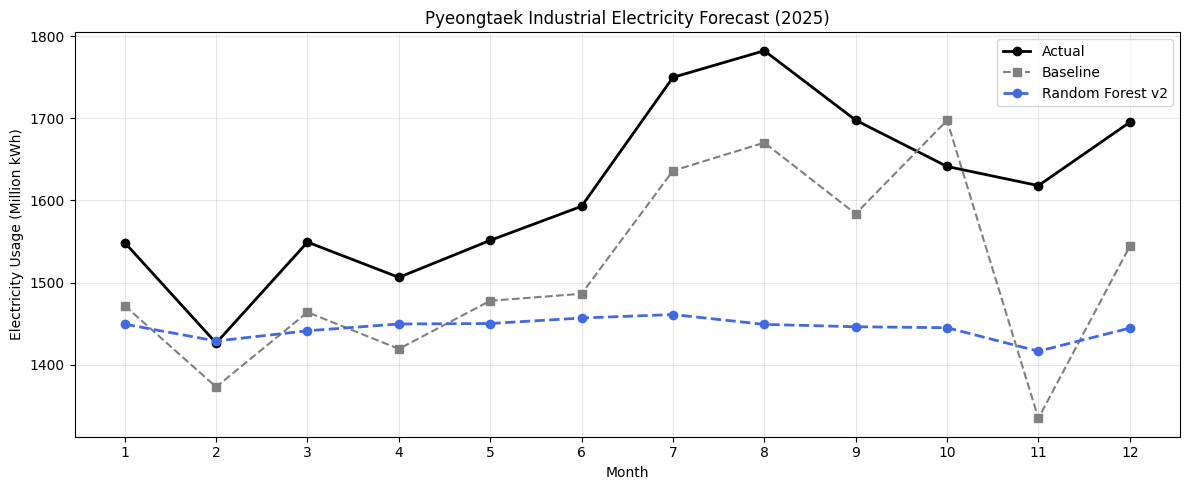

In [25]:
# STEP 28-3: 실제값과 예측값 비교

plt.figure(figsize=(12, 5))

months = sample["날짜"].dt.month

# 실제 사용량
plt.plot(
    months,
    sample["사용량"] / 1_000_000,
    marker="o",
    color="black",
    label="Actual",
    linewidth=2
)

# 기준 모델 예측값
plt.plot(
    months,
    sample["기준예측"] / 1_000_000,
    marker="s",
    color="gray",
    linestyle="--",
    label="Baseline"
)

# AI 예측값
plt.plot(
    months,
    sample["AI예측"] / 1_000_000,
    marker="o",
    color="royalblue",
    linestyle="--",
    label="Random Forest v2",
    linewidth=2
)

plt.title("Pyeongtaek Industrial Electricity Forecast (2025)")
plt.xlabel("Month")
plt.ylabel("Electricity Usage (Million kWh)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [27]:
# 평택시 기준 그냥 거의 못 맞춤
# 전체 학습 데이터의 최대 사용량
print(f"전체 학습 최대값: {y_train.max():,.0f} kWh")

# 평택시 산업용 학습 데이터
pyeongtaek_train = train[
    (train["시도"] == "경기도") &
    (train["시군구"] == "평택시") &
    (train["계약종별"] == "산업용")
]

print(f"평택시 학습 최대값: {pyeongtaek_train['사용량'].max():,.0f} kWh")

# 2025년 실제 최대 사용량
print(f"2025년 실제 최대값: {sample['사용량'].max():,.0f} kWh")

# 2025년 AI 예측 최대값
print(f"2025년 AI 예측 최대값: {sample['AI예측'].max():,.0f} kWh")

전체 학습 최대값: 1,483,386,014 kWh
평택시 학습 최대값: 1,483,386,014 kWh
2025년 실제 최대값: 1,782,184,762 kWh
2025년 AI 예측 최대값: 1,461,068,650 kWh


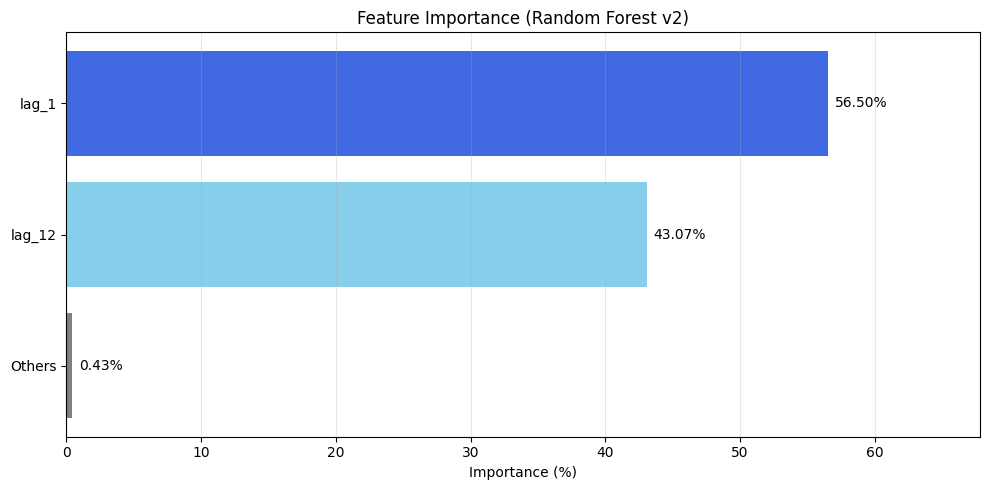

In [28]:
# 변수 중요도 시각화

# 주요 변수 중요도 추출
lag1_importance = importance.loc[
    importance["변수"] == "lag_1", "중요도"
].iloc[0]

lag12_importance = importance.loc[
    importance["변수"] == "lag_12", "중요도"
].iloc[0]

# 나머지 변수 중요도 합계
other_importance = importance.loc[
    ~importance["변수"].isin(["lag_1", "lag_12"]),
    "중요도"
].sum()

# 그래프 데이터 준비
labels = ["lag_1", "lag_12", "Others"]

values = np.array([
    lag1_importance,
    lag12_importance,
    other_importance
]) * 100

# 그래프 생성
plt.figure(figsize=(10, 5))

bars = plt.barh(
    labels,
    values,
    color=["royalblue", "skyblue", "gray"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=5)
plt.gca().invert_yaxis()

plt.title("Feature Importance (Random Forest v2)")
plt.xlabel("Importance (%)")
plt.xlim(0, max(values) * 1.2)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

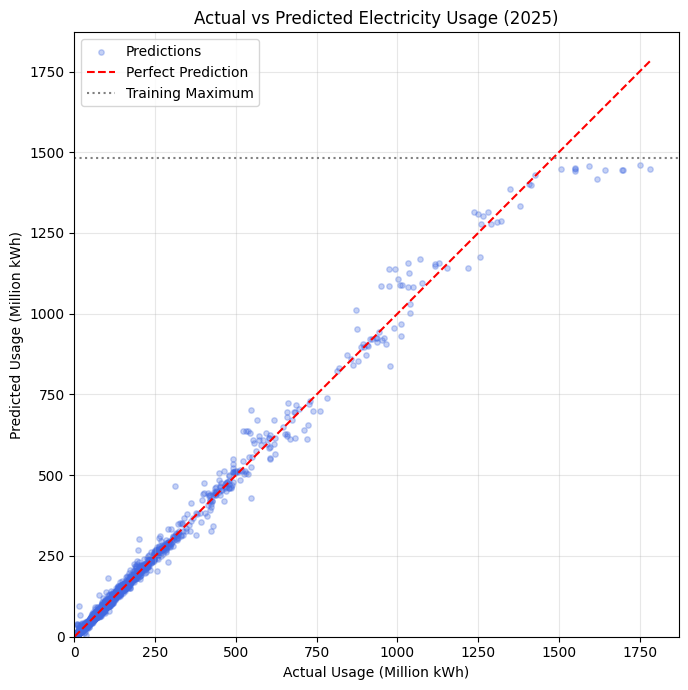

In [30]:
# 실제값과 예측값 산점도

# 백만 kWh 단위로 변환
actual = y_test / 1_000_000
predicted = rf_test_pred / 1_000_000

plt.figure(figsize=(9, 7))

# 산점도 생성
plt.scatter(
    actual,
    predicted,
    alpha=0.3,
    s=15,
    color="royalblue",
    label="Predictions"
)

# 완벽한 예측 기준선
max_value = max(actual.max(), predicted.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

# 학습 데이터 최대값 표시
plt.axhline(
    y_train.max() / 1_000_000,
    color="gray",
    linestyle=":",
    label="Training Maximum"
)

plt.title("Actual vs Predicted Electricity Usage (2025)")
plt.xlabel("Actual Usage (Million kWh)")
plt.ylabel("Predicted Usage (Million kWh)")

plt.xlim(0, max_value * 1.05)
plt.ylim(0, max_value * 1.05)
plt.gca().set_aspect("equal", adjustable="box")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()